# In-Class Task: Boosting — AdaBoost vs Gradient Boosting vs XGBoost

**Submit:** this notebook with all cells run + answers to the reflection questions

## The problem
A hospital wants a model that flags whether a breast tumour is **malignant** or **benign** from 30 measurements taken from a digitised biopsy image (radius, texture, smoothness, …). You will build three boosting models on the same data and decide which one you would recommend.

## What you'll practise
1. Fitting **AdaBoost**, **Gradient Boosting** and **XGBoost** with scikit-learn / xgboost
2. Comparing models fairly (same split, same metrics)
3. Seeing how the number of trees and the learning rate change performance
4. Reading feature importances

Find every `# TODO` and replace the `...` with your code. Don't change the `random_state` values — that way everyone's numbers are comparable.

> If `xgboost` isn't installed, run `pip install xgboost` in a cell (or `!pip install xgboost` in Colab).

## Part 0 — Setup

In [231]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier

RANDOM_STATE = 42
warnings.filterwarnings("ignore", category=UserWarning)  # hides a harmless feature-name warning

## Part 1 — Load and explore the data
In this dataset the target is `0 = malignant`, `1 = benign`.

In [232]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

# TODO 1a: print the shape of X (rows, columns)
...
print("Shape of X:", X.shape)

# TODO 1b: print how many samples are in each class (hint: y.value_counts())
...

X.head()

Shape of X: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**Q1.** Is the dataset balanced? Why does that matter when you choose a metric?

*Your answer:*

In [233]:
# TODO 1c: split into 80% train / 20% test.
# Use stratify=y and random_state=RANDOM_STATE
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, stratify=y, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## Part 2 — A helper so every model is judged the same way
This function is done for you. Read it so you know what it returns.

In [234]:
results = []

def evaluate(name, model):
    """Fit the model, time it, and store test-set metrics."""
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    row = {
        "model": name,
        "train_acc": accuracy_score(y_train, model.predict(X_train)),
        "test_acc": accuracy_score(y_test, pred),
        "test_f1": f1_score(y_test, pred),
        "test_roc_auc": roc_auc_score(y_test, proba),
        "fit_seconds": fit_seconds,
    }
    results.append(row)
    print(f"{name}: test accuracy = {row['test_acc']:.3f}, ROC AUC = {row['test_roc_auc']:.3f}")
    return model

### Baseline: a single decision stump
Boosting combines many *weak learners*. A depth-1 tree ("stump") is the classic weak learner, so let's see how well **one** of them does on its own.

In [235]:
stump = evaluate("Single stump", DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE))

Single stump: test accuracy = 0.921, ROC AUC = 0.908


## Part 3 — AdaBoost 
AdaBoost trains stumps one after another. After each round it **increases the weight of the samples it got wrong**, so the next stump focuses on the hard cases.

Build an `AdaBoostClassifier` with:
- `estimator=DecisionTreeClassifier(max_depth=1)`
- `n_estimators=200`
- `learning_rate=0.5`
- `random_state=RANDOM_STATE`

In [236]:
# TODO 3: create the AdaBoost model and pass it to evaluate()
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE)
ada = evaluate("AdaBoost", ada)

AdaBoost: test accuracy = 0.956, ROC AUC = 0.985


## Part 4 — Gradient Boosting 
Gradient Boosting also adds trees one after another, but each new tree is fitted to the **residual errors (the negative gradient of the loss)** of the model so far, rather than re-weighting samples.

Build a `GradientBoostingClassifier` with:
- `n_estimators=200`
- `learning_rate=0.1`
- `max_depth=3`
- `random_state=RANDOM_STATE`

In [237]:
# TODO 4: create the Gradient Boosting model and pass it to evaluate()
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE)
gb = evaluate("Gradient Boosting", gb)

Gradient Boosting: test accuracy = 0.956, ROC AUC = 0.990


## Part 5 — XGBoost 
XGBoost is an optimised implementation of gradient boosting. It adds **regularisation** on the trees, uses second-order gradient information, and is built for speed.

Build an `XGBClassifier` with:
- `n_estimators=200`
- `learning_rate=0.1`
- `max_depth=3`
- `eval_metric="logloss"`
- `random_state=RANDOM_STATE`

In [238]:
# TODO 5: create the XGBoost model and pass it to evaluate()
xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, eval_metric="logloss", random_state=RANDOM_STATE)
xgb = evaluate("XGBoost", xgb)

XGBoost: test accuracy = 0.947, ROC AUC = 0.992


## Part 6 — Compare the models

In [239]:
# TODO 6: turn `results` into a DataFrame, sort it by test_roc_auc (highest first) and display it rounded to 3 decimals
summary = {
    
}
df = pd.DataFrame(summary)
summary

{}

In medicine, missing a malignant tumour (predicting *benign* when it is *malignant*) is the costly mistake. The cell below shows each model's confusion matrix. Rows are the true class, columns the predicted class, in the order [malignant, benign].

In [240]:
for name, model in [("AdaBoost", ada), ("Gradient Boosting", gb), ("XGBoost", xgb)]:
    print(name)
    print(confusion_matrix(y_test, model.predict(X_test)), "\n")

AdaBoost
[[38  4]
 [ 1 71]] 

Gradient Boosting
[[38  4]
 [ 1 71]] 

XGBoost
[[38  4]
 [ 2 70]] 



**Q2.** Which model has the best test ROC AUC? Which one is fastest to train? Which one misses the fewest malignant tumours?

**Q3.** Compare `train_acc` with `test_acc`. Does any model look like it is overfitting?

*Your answers:*

## Part 7 — How many trees do you need? 
Boosting models can show you their prediction after *each* tree is added:
- scikit-learn models have `.staged_predict(X)` which yields predictions after tree 1, 2, 3, …
- XGBoost uses `.predict(X, iteration_range=(0, k))` to use only the first `k` trees

The AdaBoost curve is done for you. Complete the other two and run the cell.

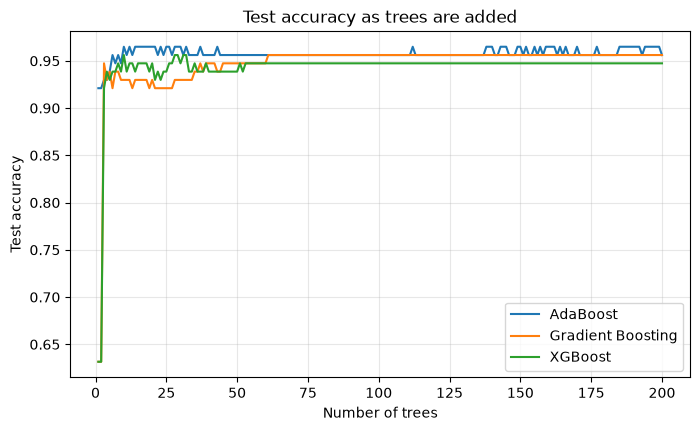

In [241]:
n_trees = np.arange(1, 201)

ada_curve = [accuracy_score(y_test, p) for p in ada.staged_predict(X_test)]

# TODO 7a: same idea for Gradient Boosting using gb.staged_predict
gb_curve = [accuracy_score(y_test, p) for p in gb.staged_predict(X_test)]

# TODO 7b: for XGBoost, loop k over n_trees and use xgb.predict(X_test, iteration_range=(0, k))
xgb_curve = [accuracy_score(y_test, xgb.predict(X_test, iteration_range=(0, k))) for k in n_trees]

plt.figure(figsize=(8, 4.5))
plt.plot(n_trees, ada_curve, label="AdaBoost")
plt.plot(n_trees, gb_curve, label="Gradient Boosting")
plt.plot(n_trees, xgb_curve, label="XGBoost")
plt.xlabel("Number of trees")
plt.ylabel("Test accuracy")
plt.title("Test accuracy as trees are added")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Q4.** Roughly how many trees does each model need before test accuracy stops improving? Would 200 trees be wasteful for any of them?

*Your answer:*

## Part 8 — The learning rate trade-off
Refit **Gradient Boosting** with three learning rates and the same 200 trees. Record test accuracy for each.

In [242]:
for lr in [0.01, 0.1, 1.0]:
    # TODO 8: build a GradientBoostingClassifier with this learning rate
    # (n_estimators=200, max_depth=3, random_state=RANDOM_STATE), fit it on the training data,
    # and print the learning rate with its test accuracy
    ...

    gbc = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=RANDOM_STATE)
    gbc.fit(X_train, y_train)
    print(gbc.score(X_test, y_test))

0.956140350877193
0.956140350877193
0.956140350877193


**Q5.** What happens with a very small learning rate and only 200 trees? What happens with a very large one? How are `learning_rate` and `n_estimators` related?

*Your answer:*

## Part 9 — What do the models look at? 
All three models expose `.feature_importances_`. The cell below plots the top 10 features for each model — just run it.

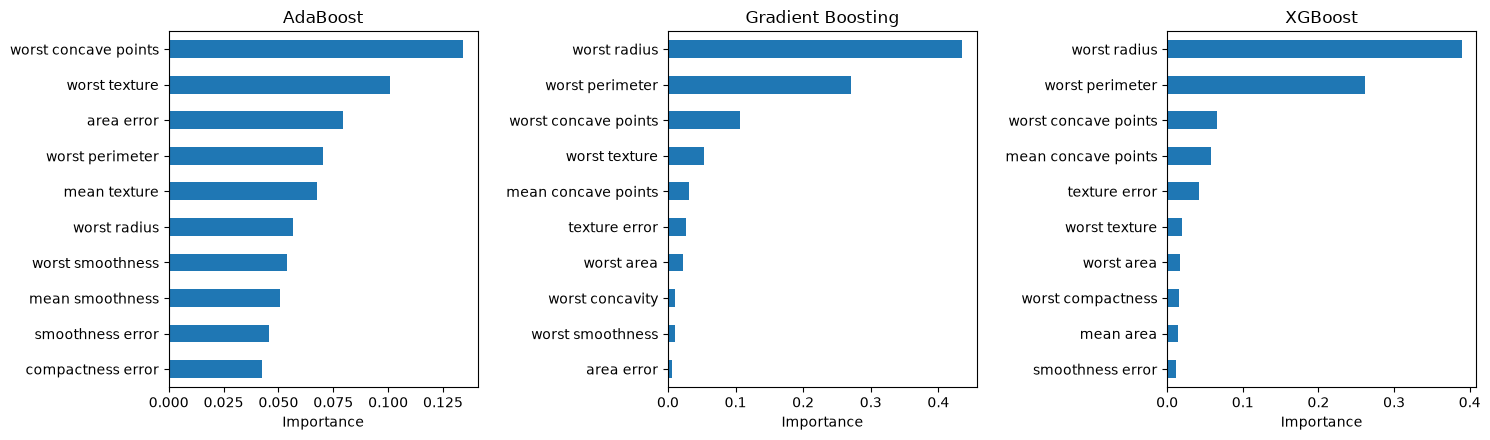

In [243]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, model) in zip(axes, [("AdaBoost", ada), ("Gradient Boosting", gb), ("XGBoost", xgb)]):
    top = pd.Series(model.feature_importances_, index=X.columns).nlargest(10).sort_values()
    top.plot.barh(ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

**Q6.** Do the three models agree on which features matter most? Name two features that appear in all three top-10 lists.

*Your answer:*

## Part 10 — Your recommendation
**Q7.** The hospital asks you which model to deploy. In 3–4 sentences, recommend one and justify it using **at least two** pieces of evidence from this notebook (metrics, confusion matrix, training time, number of trees needed, …).

*Your answer:*